<a href="https://colab.research.google.com/github/XuningZhuang/MSSP6070/blob/main/WeeklyModules/Week13/Week_13_Exercise_Xuning_Zhuang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install yfinance

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [3]:
#Task 1
start_date = '2023-01-01'
end_date = '2024-01-01'

aapl = yf.Ticker('AAPL').history(start=start_date, end=end_date, auto_adjust=False)   # auto_adjust=False prevents yfinance from automatically adjusting the Close price, preserving both the raw Close and Adj Close columns.
meta = yf.Ticker('META').history(start=start_date, end=end_date, auto_adjust=False)
goog = yf.Ticker('GOOG').history(start=start_date, end=end_date, auto_adjust=False)
nflx = yf.Ticker('NFLX').history(start=start_date, end=end_date, auto_adjust=False)

print('Apple:', aapl.shape)
print('Facebook/Meta:', meta.shape)
print('Google:', goog.shape)
print('Netflix:', nflx.shape)
print('\nApple sample:')
print(aapl.head())

for ticker, stock in [('AAPL', aapl), ('META', meta), ('GOOG', goog), ('NFLX', nflx)]:
    if stock.empty:
        raise ValueError('No price history returned for ' + ticker + '. Check your internet connection and try again.')
#this means do not continue silently when Yahoo Finance returns no stock history.

Apple: (250, 8)
Facebook/Meta: (250, 8)
Google: (250, 8)
Netflix: (250, 8)

Apple sample:
                            Open   High    Low  Close  Adj Close     Volume  \
Date                                                                          
2023-01-03 00:00:00-05:00 130.28 130.90 124.17 125.07     122.78  112117500   
2023-01-04 00:00:00-05:00 126.89 128.66 125.08 126.36     124.05   89113600   
2023-01-05 00:00:00-05:00 127.13 127.77 124.76 125.02     122.73   80962700   
2023-01-06 00:00:00-05:00 126.01 130.29 124.89 129.62     127.25   87754700   
2023-01-09 00:00:00-05:00 130.47 133.41 129.89 130.15     127.77   70790800   

                           Dividends  Stock Splits  
Date                                                
2023-01-03 00:00:00-05:00       0.00          0.00  
2023-01-04 00:00:00-05:00       0.00          0.00  
2023-01-05 00:00:00-05:00       0.00          0.00  
2023-01-06 00:00:00-05:00       0.00          0.00  
2023-01-09 00:00:00-05:00       0.00  

In [4]:
#Task 2
aapl['ticker'] = 'AAPL'    #This adds a new column named ticker to each individual DataFrame containing the corresponding stock symbol
meta['ticker'] = 'META'
goog['ticker'] = 'GOOG'
nflx['ticker'] = 'NFLX'

combined = pd.concat([aapl, meta, goog, nflx])
combined = combined.reset_index()
combined['Date'] = pd.to_datetime(combined['Date']).dt.tz_localize(None)
combined = combined[['Date', 'ticker', 'Open', 'High', 'Low', 'Close', 'Volume']]
combined = combined.sort_values(['Date', 'ticker'])

print('Combined DataFrame size:', combined.shape)
print(combined.head(8))
print('\nRows per ticker:')
print(combined['ticker'].value_counts())

Combined DataFrame size: (1000, 7)
          Date ticker   Open   High    Low  Close     Volume
0   2023-01-03   AAPL 130.28 130.90 124.17 125.07  112117500
500 2023-01-03   GOOG  89.83  91.55  89.02  89.70   20738500
250 2023-01-03   META 122.82 126.37 122.28 124.74   35528500
750 2023-01-03   NFLX  29.81  29.84  28.87  29.50   67640000
1   2023-01-04   AAPL 126.89 128.66 125.08 126.36   89113600
501 2023-01-04   GOOG  91.01  91.24  87.80  88.71   27046500
251 2023-01-04   META 127.38 129.05 125.85 127.37   32397100
751 2023-01-04   NFLX  29.82  31.11  29.55  30.94   93451000

Rows per ticker:
ticker
AAPL    250
GOOG    250
META    250
NFLX    250
Name: count, dtype: int64


In [5]:
#Task 3
metrics = ['quickRatio', 'currentRatio', 'totalRevenue', 'debtToEquity', 'revenuePerShare', 'returnOnAssets', 'returnOnEquity', 'grossProfits']

financial_data = {}

for ticker in ['AAPL', 'META', 'GOOG', 'NFLX']:
    try:
        company_info = yf.Ticker(ticker).info
        financial_data[ticker] = [company_info.get(metric, float('nan')) for metric in metrics]
        print(ticker, '- financial metrics retrieved')
    except Exception as error:
        print(ticker, '- unable to retrieve financial metrics:', error)
        financial_data[ticker] = [float('nan')] * len(metrics)

financial_stats = pd.DataFrame(financial_data, index=metrics).T

print('\nFinancial metrics by stock:')
print(financial_stats)

AAPL - financial metrics retrieved
META - financial metrics retrieved
GOOG - financial metrics retrieved
NFLX - financial metrics retrieved

Financial metrics by stock:
      quickRatio  currentRatio    totalRevenue  debtToEquity  revenuePerShare  \
AAPL        0.83          1.02 478833999872.00         84.29            32.66   
META        1.67          1.90 241605001216.00         42.16            95.19   
GOOG        2.51          2.79 471097999360.00         22.19            38.79   
NFLX        0.84          1.07  49734631424.00         59.86            11.86   

      returnOnAssets  returnOnEquity    grossProfits  
AAPL            0.26            1.42 233602007040.00  
META            0.15            0.32 195782000640.00  
GOOG            0.13            0.44 286698012672.00  
NFLX            0.17            0.53  25207793664.00  


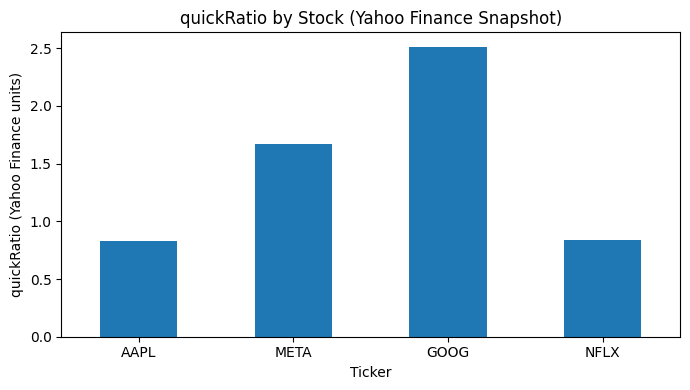

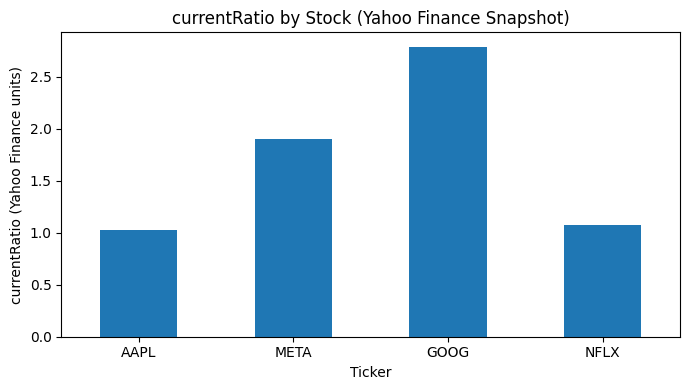

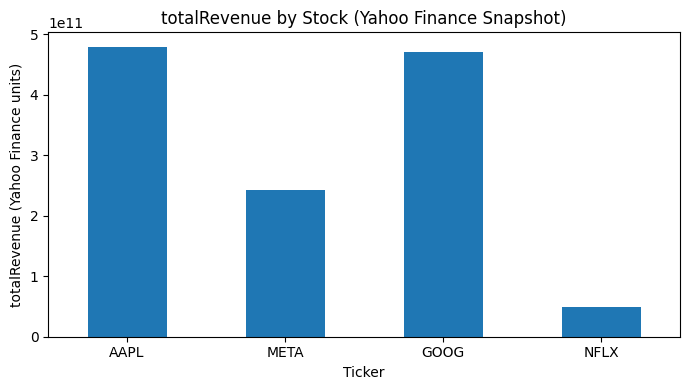

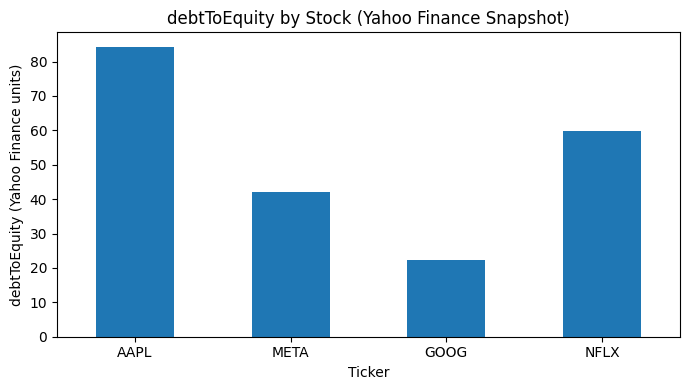

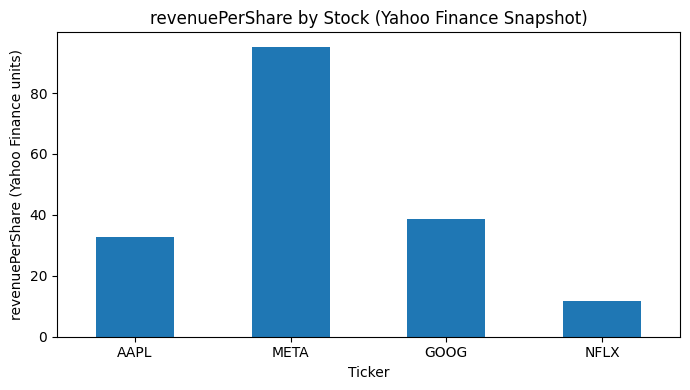

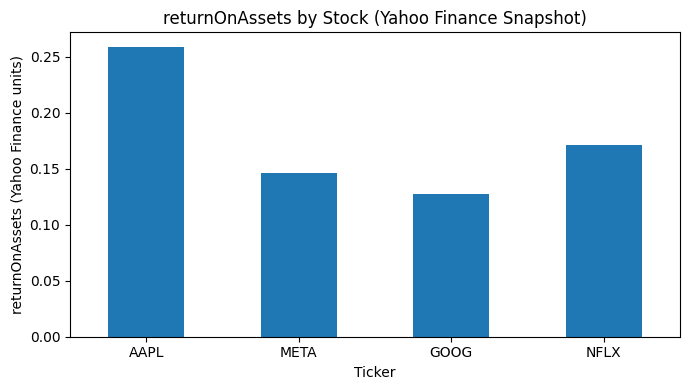

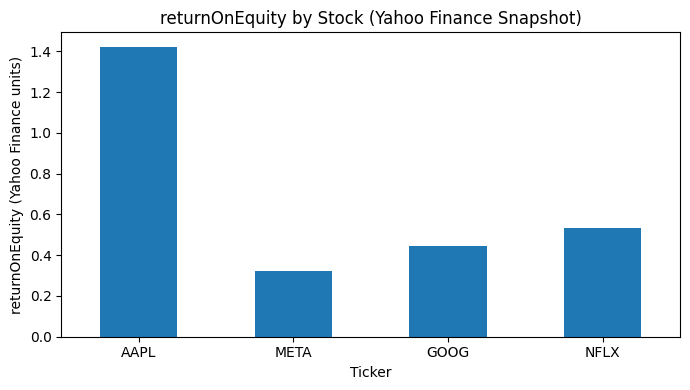

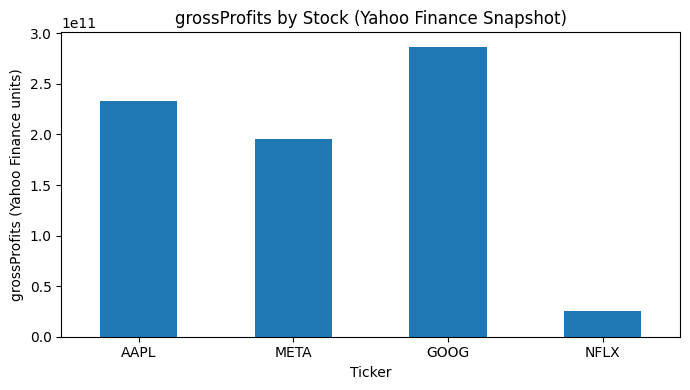

In [6]:
#Task 4
for metric in metrics:
    values = financial_stats[metric].dropna()

    if len(values) == 0:
        print(metric, ': no available data, so no chart was created.')
        continue

    values.plot(kind='bar', figsize=(7, 4))
    plt.title(metric + ' by Stock (Yahoo Finance Snapshot)')
    plt.xlabel('Ticker')
    plt.ylabel(metric + ' (Yahoo Finance units)')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

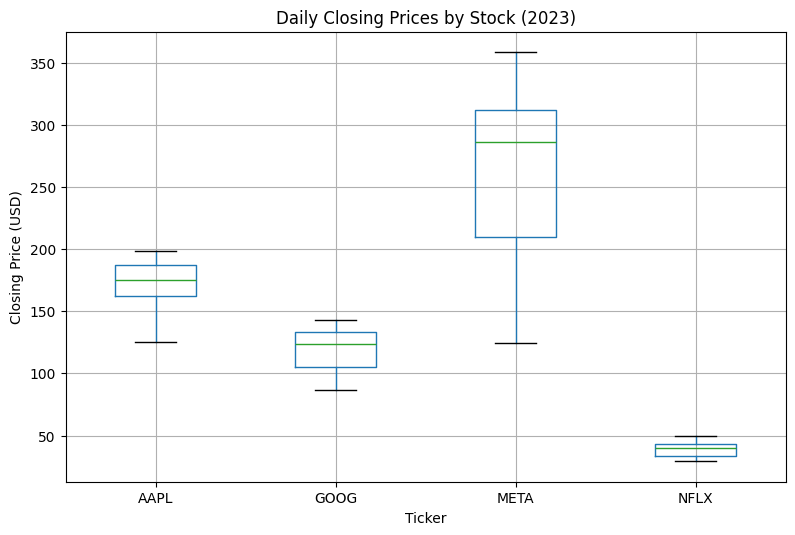

In [7]:
combined.boxplot(column='Close', by='ticker', figsize=(9, 6))

plt.title('Daily Closing Prices by Stock (2023)')
plt.suptitle('')
plt.xlabel('Ticker')
plt.ylabel('Closing Price (USD)')
plt.show()

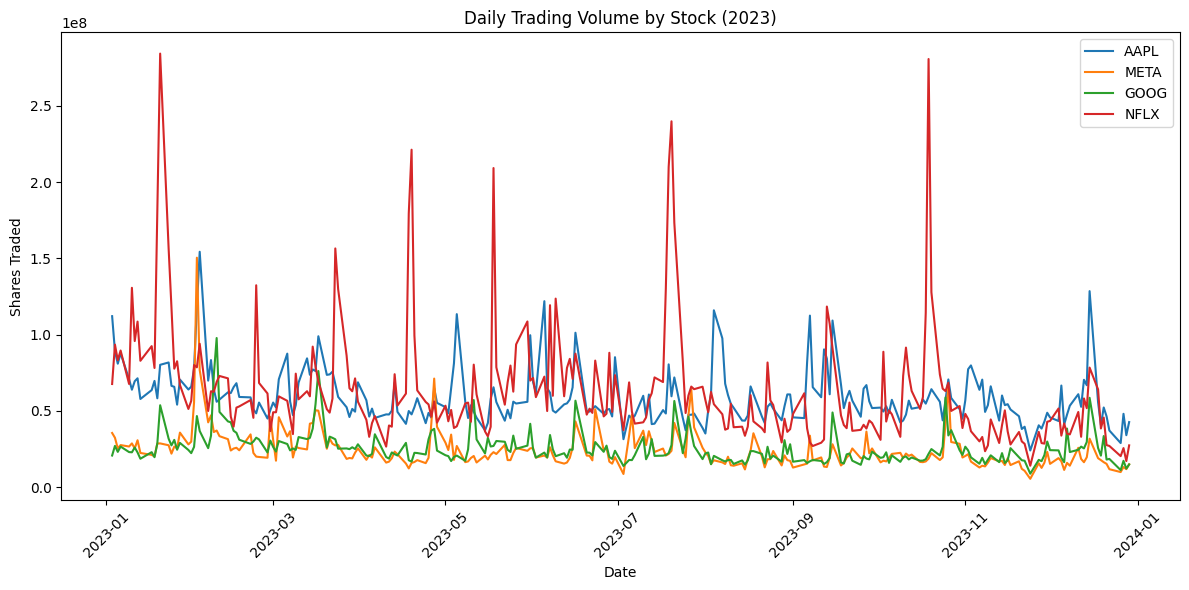

In [8]:
#Task 5
plt.figure(figsize=(12, 6))

for ticker in ['AAPL', 'META', 'GOOG', 'NFLX']:
    one_stock = combined[combined['ticker'] == ticker]
    plt.plot(one_stock['Date'], one_stock['Volume'], label=ticker)

plt.title('Daily Trading Volume by Stock (2023)')
plt.xlabel('Date')
plt.ylabel('Shares Traded')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
csv_name = 'Week13_Combined_Stock_Prices_2023.csv'
combined.to_csv(csv_name, index=False)
print('Saved in the Colab working folder:', os.path.abspath(csv_name))
print('Number of saved rows:', len(combined))

# Optional: save a separate snapshot of the eight financial metrics.
financial_stats.to_csv('Week13_Financial_Metrics_Snapshot.csv')
print('Also saved: Week13_Financial_Metrics_Snapshot.csv')

Saved in the Colab working folder: /content/Week13_Combined_Stock_Prices_2023.csv
Number of saved rows: 1000
Also saved: Week13_Financial_Metrics_Snapshot.csv
